# M10 en cuatro geologías sísmicas: modelo recuperado y evidencia de forma de onda

**Nivel 3 — Estudio numérico comparativo** · 45 min · prerrequisitos: lección M10, propagación de ondas, evaluación retenida y no unicidad inversa.


## Objetivos

Comparar cuatro estructuras sísmicas físicamente distintas y sus resultados FWI del producto con escalas comunes de velocidad y residuales. Separar verdad sintética conocida, inicio 1D independiente, receptores ajustados y retenidos, y veredicto registrado del control negativo.


## Preparación

Use el entorno fijado: `scripts/setup.ps1 -Notebooks` (Windows) o `scripts/setup.sh --notebooks` (Linux/macOS). Pines exactos: `pip install numpy==2.2.6 scipy==1.15.2 pandas==2.2.3 matplotlib==3.10.8`. Esta lección inspecciona ejecuciones del producto ya guardadas; no entrena ni vuelve a ejecutar FWI.


In [1]:
# Print exact package versions and set this notebook's display language.
SPANISH = True
from importlib.metadata import version
for package in ("numpy", "scipy", "pandas", "matplotlib"):
    print(f"{package}=={version(package)}")


numpy==2.2.6
scipy==1.15.2
pandas==3.0.6
matplotlib==3.10.8


Verificar identidad de artefactos catalogados antes de interpretar sus arreglos.


In [2]:
# Verify exact catalogued bytes before reading the four product results.
import hashlib, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"data/derived/v2/catalog.json").is_file())
catalog = json.loads((root/"data/derived/v2/catalog.json").read_text(encoding="utf-8"))
case_ids = ["FWI_LAYERED", "FWI_FAULT", "FWI_CYCLE_SKIP", "FWI_NOISY"]
records = {}
for cid in case_ids:
    entry = next(c for c in catalog["cases"] if c["id"] == cid)
    ref = next(v for v in entry["variants"] if v["id"] == "reference")
    raw = (root/"data/derived/v2"/ref["path"]).read_bytes()
    assert len(raw) == ref["bytes"] and hashlib.sha256(raw).hexdigest() == ref["sha256"]
    run = json.loads(raw)
    assert run["id"] == cid and run["variant"] == "reference"
    assert set(run["methods"]) == {"fwi-l2", "fwi-multiscale"}
    records[cid] = run
rows = []
for cid, run in records.items():
    full, multi = run["methods"]["fwi-l2"], run["methods"]["fwi-multiscale"]
    rows.append({"Case": run["name"], "Geometry": run["geometry"], "Verdict": multi["evaluation"]["status"],
      "Start RMSE m/s": multi["metrics"]["initial_velocity_rmse"], "Full band / start": full["metrics"]["model_rmse_ratio"],
      "Continuation / start": multi["metrics"]["model_rmse_ratio"], "Fit WRMS": multi["metrics"]["active_wrms"],
      "Held-out WRMS": multi["metrics"]["withheld_wrms"]})
table = pd.DataFrame(rows).round(3)
if SPANISH:
    table = table.rename(columns={"Case":"Caso", "Geometry":"Geometría", "Verdict":"Veredicto", "Start RMSE m/s":"RMSE inicial m/s", "Full band / start":"Banda completa / inicio", "Continuation / start":"Continuación / inicio", "Fit WRMS":"WRMS ajustado", "Held-out WRMS":"WRMS retenido"})
display(table)
print("Cuatro hashes de bytes del catálogo verificados. Observaciones e inversión usan el mismo motor directo sintético." if SPANISH else "Four catalogued byte hashes verified. Observations and inverse use the same synthetic forward engine.")
print("Todos los casos retienen receptores con índice módulo cinco igual a dos; las trazas retenidas no seleccionan estados del optimizador." if SPANISH else "All cases hold out receiver indices modulo five equal to two; held-out traces never select an optimizer state.")


,Caso,Geometría,Veredicto,RMSE inicial m/s,Banda completa / inicio,Continuación / inicio,WRMS ajustado,WRMS retenido
0,Layered reflection survey,layers,recovered,229.095,0.535,0.527,1.208,1.233
1,Normal fault displacement,normal_fault,recovered,301.203,0.701,0.653,1.340,1.388
2,Salt dome / cycle skipping,salt,negative-control,726.036,0.852,0.803,1.751,1.966
3,Low-velocity gas channel,channel,unresolved,340.618,0.660,0.521,2.071,2.213


Cuatro hashes de bytes del catálogo verificados. Observaciones e inversión usan el mismo motor directo sintético.
Todos los casos retienen receptores con índice módulo cinco igual a dos; las trazas retenidas no seleccionan estados del optimizador.


## Datos

Cuatro ejecuciones de referencia verificadas por bytes representan reflexión estratificada, falla normal desplazada, salto de ciclo por domo salino y canal de baja velocidad. Las observaciones son sintéticas y comparten el motor directo de la inversión, con ruido aditivo independiente. Se conserva esta limitación de crimen inverso.


## Método

Cada artefacto guarda el modelo verdadero, un inicio independiente de tendencia en profundidad, datos observados de tres disparos, una reserva fija de receptores e inversiones del producto de banda completa y continuación en frecuencia. El producto usa propagación de presión acústica Deepwave y L-BFGS con rugosidad de gradiente de velocidad escalada físicamente. Los métodos comparten adquisición, inicio, ruido y cuatro mallas de control espacial por caso. El registro graficado es observado menos predicho; las líneas horizontales marcan receptores retenidos.


## Estado del arte

La continuación de baja a alta frecuencia es una estrategia habitual frente al salto de ciclo: las frecuencias bajas reducen la ambigüedad de fase antes de refinar detalles con frecuencias altas. No garantiza convergencia ni unicidad. Esta matriz no compara propagadores independientes ni generalización a terreno.


## Resultados

La tabla informa RMSE del modelo relativo al inicio independiente, WRMS de ajuste y WRMS de receptores retenidos. Las cuatro estructuras distintas comparten escala de modelo de 1.400–4.400 m/s y escala residual con signo. El caso salino sigue siendo control negativo; no promedie su fallo como éxito. Una razón RMSE menor que uno indica mejora frente al inicio declarado solo para esa realización sintética.


Comparar objetivos distintos y registros residuales con receptores retenidos marcados.


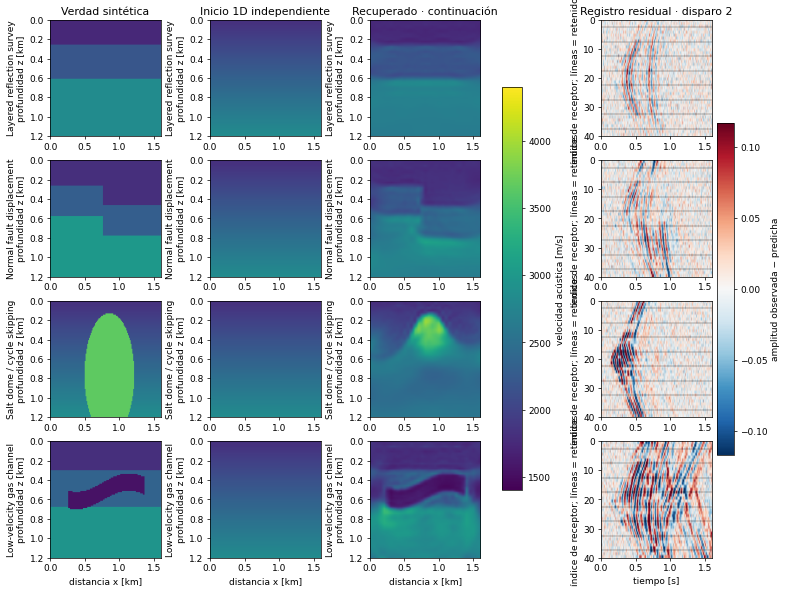

In [3]:
# Put four different geological targets and their measured residual gathers on common scales.
fig, axes = plt.subplots(4, 4, figsize=(12, 9), dpi=65, constrained_layout=True)
gathers = [np.asarray(records[c]["methods"]["fwi-multiscale"]["residual"])[1] for c in case_ids]
limit = float(np.quantile(np.concatenate([np.abs(g).ravel() for g in gathers]), .98))
im = None
for i, cid in enumerate(case_ids):
    run = records[cid]
    models = [np.asarray(run["truth"]), np.asarray(run["initial"]), np.asarray(run["methods"]["fwi-multiscale"]["model"])]
    titles = ("Verdad sintética", "Inicio 1D independiente", "Recuperado · continuación") if SPANISH else ("Known synthetic truth", "Independent 1-D start", "Recovered · frequency continuation")
    for j, (arr, title) in enumerate(zip(models, titles)):
        ax=axes[i,j]; im=ax.imshow(arr,origin="upper",aspect="auto",extent=(0,1.6,1.2,0),cmap="viridis",vmin=1400,vmax=4400)
        if i==0: ax.set_title(title)
        ax.set_ylabel(f"{run['name']}\nprofundidad z [km]" if SPANISH else f"{run['name']}\ndepth z [km]")
        if i==3: ax.set_xlabel("distancia x [km]" if SPANISH else "distance x [km]")
    ax=axes[i,3]; res=gathers[i]
    ax.imshow(res,origin="upper",aspect="auto",extent=(0,res.shape[1]*.004,res.shape[0],0),cmap="RdBu_r",vmin=-limit,vmax=limit)
    for r in np.flatnonzero(~np.asarray(run["active_receivers"],dtype=bool)): ax.axhline(r+.5,color="#111",lw=.35)
    if i==0: ax.set_title("Registro residual · disparo 2" if SPANISH else "Residual gather · shot 2")
    ax.set_ylabel("índice de receptor; líneas = retenidos" if SPANISH else "receiver index; lines = held out")
    if i==3: ax.set_xlabel("tiempo [s]" if SPANISH else "record time [s]")
fig.colorbar(im,ax=axes[:,:3],label="velocidad acústica [m/s]" if SPANISH else "acoustic velocity [m/s]",shrink=.75)
fig.colorbar(axes[0,3].images[0],ax=axes[:,3],label="amplitud observada − predicha" if SPANISH else "observed − predicted amplitude",shrink=.75)
plt.show()


Revisar razones de recuperación y consistencia de ruido por caso.


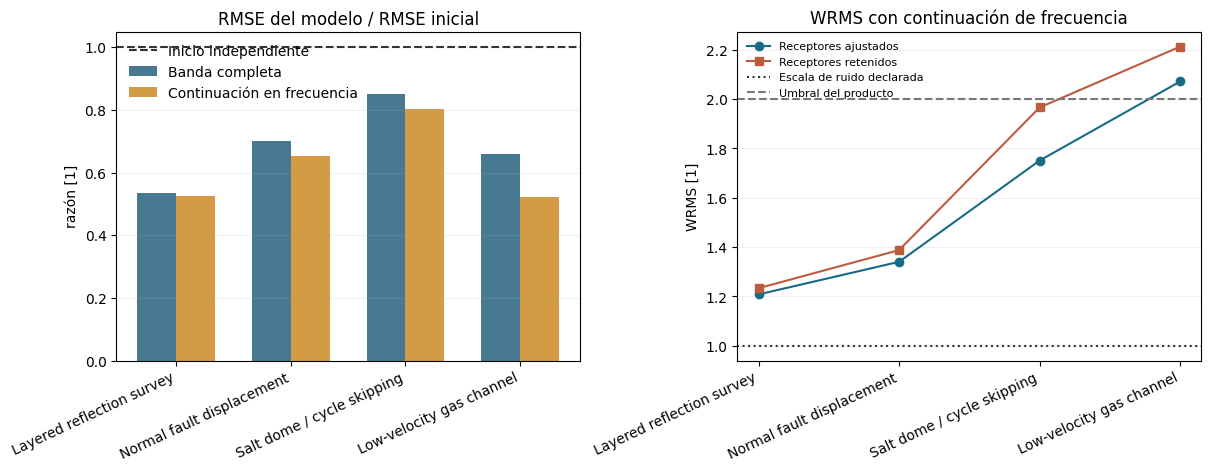

FWI_LAYERED verdict recovered reasons []
FWI_FAULT verdict recovered reasons []
FWI_CYCLE_SKIP verdict negative-control reasons ['salt_cycle_skipping_challenge']
FWI_NOISY verdict unresolved reasons ['active_data_misfit_above_declared_noise', 'withheld_data_misfit_above_declared_noise']


In [4]:
# Compare both inversions to the declared start and inspect the held-out noise scale.
fig, axes = plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
x=np.arange(len(case_ids)); w=.34
full=[records[c]["methods"]["fwi-l2"]["metrics"]["model_rmse_ratio"] for c in case_ids]
multi=[records[c]["methods"]["fwi-multiscale"]["metrics"]["model_rmse_ratio"] for c in case_ids]
active=[records[c]["methods"]["fwi-multiscale"]["metrics"]["active_wrms"] for c in case_ids]
held=[records[c]["methods"]["fwi-multiscale"]["metrics"]["withheld_wrms"] for c in case_ids]
names=[records[c]["name"] for c in case_ids]
axes[0].bar(x-w/2,full,w,label="Banda completa" if SPANISH else "Full band",color="#477a92"); axes[0].bar(x+w/2,multi,w,label="Continuación en frecuencia" if SPANISH else "Frequency continuation",color="#d39b43")
axes[0].axhline(1,color="#333",ls="--",label="Inicio independiente" if SPANISH else "Independent start"); axes[0].set(title="RMSE del modelo / RMSE inicial" if SPANISH else "Model RMSE / start RMSE",ylabel="razón [1]" if SPANISH else "ratio [1]"); axes[0].legend(frameon=False)
axes[1].plot(x,active,"o-",label="Receptores ajustados" if SPANISH else "Fitted receivers",color="#176b87"); axes[1].plot(x,held,"s-",label="Receptores retenidos" if SPANISH else "Withheld receivers",color="#bd5b3d")
axes[1].axhline(1,color="#333",ls=":",label="Escala de ruido declarada" if SPANISH else "Declared noise scale"); axes[1].axhline(2,color="#777",ls="--",label="Umbral del producto" if SPANISH else "Product threshold")
axes[1].set(title="WRMS con continuación de frecuencia" if SPANISH else "Frequency-continuation WRMS",ylabel="WRMS [1]"); axes[1].legend(frameon=False,fontsize=8)
for ax in axes: ax.set_xticks(x,names,rotation=25,ha="right"); ax.grid(axis="y",alpha=.18)
plt.show()
for cid in case_ids:
    m=records[cid]["methods"]["fwi-multiscale"]
    print(cid, "verdict", m["evaluation"]["status"], "reasons", m["evaluation"]["reason_codes"])


## Resumen

Cuatro casos sintéticos no son cuatro validaciones independientes de terreno. La reserva de receptores comparte apertura y las observaciones comparten motor con la inversión. Mejores puntajes de modelo o datos no establecen geología única, transferencia a terreno ni incertidumbre calibrada. Interprete el fallo salino y los patrones distintos de falla/canal junto con los agregados.


## Referencias

- [Tutorial FWI de onda completa de Devito](https://www.devitoproject.org/examples/seismic/tutorials/03_fwi.html) — contexto de formulación en fuente primaria; las ejecuciones usan el motor Deepwave fijado del repositorio.
- [Método y límites de FWI acústica M10](../../../docs/problem-types/02_fwi-recovery.md).
